# Distribution of the Relevance Scores

| Item | Description |
|---|---|
| Goal | Figure A of the plan: for each relevance measure, one single-panel histogram of the firm scores on the three-year sample, with a dashed line at the median. |
| Input | `output/T3.8.3/firm_relevance_scores_wide.csv` (T3.8.3). |
| Output | `output/T3.9.1/fig_distribution_<method>_<vector>_<measure>.{png,svg,pdf}`, one figure per measure. |
| Unit | A firm (gvkey) in the three-year sample (fiscal 2010, 2015, 2020; 841 firms). |
| Measures | The eight non-binary measures of T3.8.3: the sentence share for the definition and centroid vectors; the firm-summary and yearly-mean cosines for the definition, centroid, and policy summary vectors. The two binary measures take only the values 0 and 1 and are reported in the Notes of the share figures instead. |
| Style | S3: 9 by 6 inches, Times, 0.5 cm margins, no text inside the plot, title and notes in Markdown below. |

See `Topic Relevance Rebuild Plan.md` in the TEMP folder for the surrounding steps and `T3.8.3` for what each measure is.


## Step 1. Import packages


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display


## Step 2. Define file locations and the measures to plot


In [2]:
PROJECT_FOLDER = Path("/project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis")
NOTEBOOK_SUBFOLDER = Path("T3 - Topic Relevance and Corporate Disclosure/TEMP")
NOTEBOOK_NAME = "T3.9.1"  # the identifier names this notebook's output folder
TEMP_OUTPUT = PROJECT_FOLDER / NOTEBOOK_SUBFOLDER / "output"
OUTPUT_FOLDER = TEMP_OUTPUT / NOTEBOOK_NAME
SCORES_FILE = TEMP_OUTPUT / "T3.8.3/firm_relevance_scores_wide.csv"

SAMPLE = "three_years"
N_BINS = 30
VECTOR_WORDS = {"definition": "the topic definition", "centroid": "the statement centroid", "policy_summary": "the policy summary"}
# measure_id -> (file stem, x-title, one-sentence description for the Notes)
MEASURES = {
    "sentences | definition | share": ("fig_distribution_sentences_definition_share",
        "Share of Item 1 sentences at or above the definition threshold (share)",
        "the number of the firm's Item 1 sentences whose cosine with the topic definition is at or above 0.67, divided by all its Item 1 sentences in the sample"),
    "sentences | centroid | share": ("fig_distribution_sentences_centroid_share",
        "Share of Item 1 sentences at or above the centroid threshold (share)",
        "the number of the firm's Item 1 sentences whose cosine with the statement centroid is at or above 0.75, divided by all its Item 1 sentences in the sample"),
    "summaries | definition | firm_summary": ("fig_distribution_summaries_definition_firm_summary",
        "Cosine between the firm summary and the topic definition (cosine)",
        "the cosine between the embedding of the firm's summary of its Item 1 sections and the embedding of the topic definition"),
    "summaries | definition | yearly_mean": ("fig_distribution_summaries_definition_yearly_mean",
        "Mean cosine between the yearly summaries and the topic definition (cosine)",
        "the cosine between each yearly Item 1 summary and the topic definition, averaged over the firm's fiscal years in the sample"),
    "summaries | centroid | firm_summary": ("fig_distribution_summaries_centroid_firm_summary",
        "Cosine between the firm summary and the statement centroid (cosine)",
        "the cosine between the embedding of the firm's summary of its Item 1 sections and the centroid of the Topic 68 hearing statements"),
    "summaries | centroid | yearly_mean": ("fig_distribution_summaries_centroid_yearly_mean",
        "Mean cosine between the yearly summaries and the statement centroid (cosine)",
        "the cosine between each yearly Item 1 summary and the centroid of the Topic 68 hearing statements, averaged over the firm's fiscal years in the sample"),
    "summaries | policy_summary | firm_summary": ("fig_distribution_summaries_policy_summary_firm_summary",
        "Cosine between the firm summary and the policy summary (cosine)",
        "the cosine between the embedding of the firm's summary of its Item 1 sections and the embedding of the policy summary of the Topic 68 hearing statements"),
    "summaries | policy_summary | yearly_mean": ("fig_distribution_summaries_policy_summary_yearly_mean",
        "Mean cosine between the yearly summaries and the policy summary (cosine)",
        "the cosine between each yearly Item 1 summary and the policy summary of the Topic 68 hearing statements, averaged over the firm's fiscal years in the sample"),
}
SOURCE = "10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; authors' calculations"
OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)
print(f"Outputs: {OUTPUT_FOLDER}")


Outputs: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T3 - Topic Relevance and Corporate Disclosure/TEMP/output/T3.9.1


## Step 3. Figure style

The S3 settings: canvas, font, colors, horizontal background lines only.


In [3]:
RED = "#B31942"
BLUE = "#0A3161"
MIDNIGHT_BLUE = "#004953"
GREY = "#A6A6A8"
BLACK = "#101820"
FIGURE_WIDTH = 9
FIGURE_HEIGHT = 6
MARGIN_INCHES = 0.5 / 2.54
REFERENCE_LINE_WIDTH = 0.8
EXPORT_DPI = 300

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "Times", "Liberation Serif", "DejaVu Serif"]
plt.rcParams["font.size"] = 11
plt.rcParams["figure.figsize"] = (FIGURE_WIDTH, FIGURE_HEIGHT)
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["axes.unicode_minus"] = True
plt.rcParams["axes.grid"] = True
plt.rcParams["axes.grid.axis"] = "y"
plt.rcParams["axes.axisbelow"] = True
plt.rcParams["grid.color"] = GREY
plt.rcParams["grid.linewidth"] = 0.5
plt.rcParams["text.color"] = BLACK
plt.rcParams["axes.labelcolor"] = BLACK
plt.rcParams["axes.edgecolor"] = BLACK
plt.rcParams["xtick.color"] = BLACK
plt.rcParams["ytick.color"] = BLACK


## Step 4. Load the scores

The wide table of T3.8.3, three-year sample only; every measure column must be present.


In [4]:
wide = pd.read_csv(SCORES_FILE, dtype={"gvkey": str})
wide = wide.loc[wide["sample"].eq(SAMPLE)].reset_index(drop=True)
missing_columns = [m for m in MEASURES if m not in wide.columns]
assert not missing_columns, missing_columns
print(f"Firms in the {SAMPLE} sample: {len(wide):,}")
display(wide[list(MEASURES)].describe().loc[["count", "min", "50%", "max"]].round(3).T)


Firms in the three_years sample: 841


,count,min,50%,max
sentences | definition | share,841.0,0.000,0.000,0.037
sentences | centroid | share,841.0,0.000,0.000,0.027
summaries | definition | firm_summary,841.0,0.309,0.433,0.553
summaries | definition | yearly_mean,841.0,0.322,0.434,0.538
summaries | centroid | firm_summary,841.0,0.419,0.503,0.593
summaries | centroid | yearly_mean,841.0,0.397,0.500,0.597
summaries | policy_summary | firm_summary,841.0,0.401,0.512,0.622
summaries | policy_summary | yearly_mean,841.0,0.387,0.507,0.626


## Step 5. Draw one histogram per measure

Bars in BLUE, the median as a dashed BLACK line, no text inside the plot. Positions are measured after drawing so that the Y-title starts 0.5 cm from the left edge and the X-title ends 0.5 cm above the bottom edge; there is no legend because the figure has one series.


In [5]:
figure_records = []
for figure_number, (measure_id, (figure_name, x_title, description)) in enumerate(MEASURES.items(), start=1):
    values = wide[measure_id].dropna().to_numpy()
    median = float(np.median(values))
    is_share = measure_id.endswith("| share")
    lower = 0.0 if is_share else float(values.min())
    upper = float(values.max())
    edges = np.linspace(lower, upper, N_BINS + 1)

    figure, axis = plt.subplots()
    figure.subplots_adjust(left=0.1, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=1 - MARGIN_INCHES / FIGURE_HEIGHT, bottom=0.15)
    axis.hist(values, bins=edges, color=BLUE, edgecolor="white", linewidth=0.4, zorder=2)
    axis.axvline(median, color=BLACK, linestyle="--", linewidth=REFERENCE_LINE_WIDTH, zorder=3)
    axis.set_xlim(lower - (upper - lower) * 0.02, upper + (upper - lower) * 0.02)
    axis.set_xlabel(x_title)
    axis.set_ylabel("Number of firms")
    axis.spines[["top", "right"]].set_visible(False)

    figure.canvas.draw()
    renderer = figure.canvas.get_renderer()
    margin_pixels = MARGIN_INCHES * figure.dpi
    left_shift = (margin_pixels - axis.yaxis.label.get_window_extent(renderer).x0) / figure.bbox.width
    bottom_shift = (margin_pixels - axis.xaxis.label.get_window_extent(renderer).y0) / figure.bbox.height
    figure.subplots_adjust(left=figure.subplotpars.left + left_shift, bottom=figure.subplotpars.bottom + bottom_shift)
    for extension in ["png", "svg", "pdf"]:
        figure.savefig(OUTPUT_FOLDER / f"{figure_name}.{extension}", dpi=EXPORT_DPI)
    plt.close(figure)

    method, vector, measure = [part.strip() for part in measure_id.split("|")]
    if is_share:
        n_zero = int((values == 0).sum())
        extra = f" {n_zero:,} of the {len(values):,} firms have no sentence at or above the threshold and score 0, so the binary measure for this vector equals 1 for {len(values) - n_zero:,} firms."
    else:
        extra = ""
    notes = (f"Each bar counts firms in the three-year sample (fiscal years 2010, 2015, and 2020; {len(wide):,} firms) by their score, which is {description}, "
             f"compared with {VECTOR_WORDS[vector]} of Topic 68, consumer data privacy legislation. {N_BINS} bins of equal width from {lower:.3f} to {upper:.3f}. "
             f"The dashed line marks the median, {median:.3f}.{extra}")
    figure_records.append((figure_number, figure_name, measure_id, notes))
    print(f"Figure {figure_number}: {figure_name} ({len(values):,} firms, median {median:.3f})")


Figure 1: fig_distribution_sentences_definition_share (841 firms, median 0.000)
Figure 2: fig_distribution_sentences_centroid_share (841 firms, median 0.000)


Figure 3: fig_distribution_summaries_definition_firm_summary (841 firms, median 0.433)
Figure 4: fig_distribution_summaries_definition_yearly_mean (841 firms, median 0.434)


Figure 5: fig_distribution_summaries_centroid_firm_summary (841 firms, median 0.503)


Figure 6: fig_distribution_summaries_centroid_yearly_mean (841 firms, median 0.500)
Figure 7: fig_distribution_summaries_policy_summary_firm_summary (841 firms, median 0.512)


Figure 8: fig_distribution_summaries_policy_summary_yearly_mean (841 firms, median 0.507)


## Step 6. Show the figures

Title, image, Notes, and Source for each figure, in that order.


**Figure 1. Distribution of the Share of Sentences with the Definition Vector**

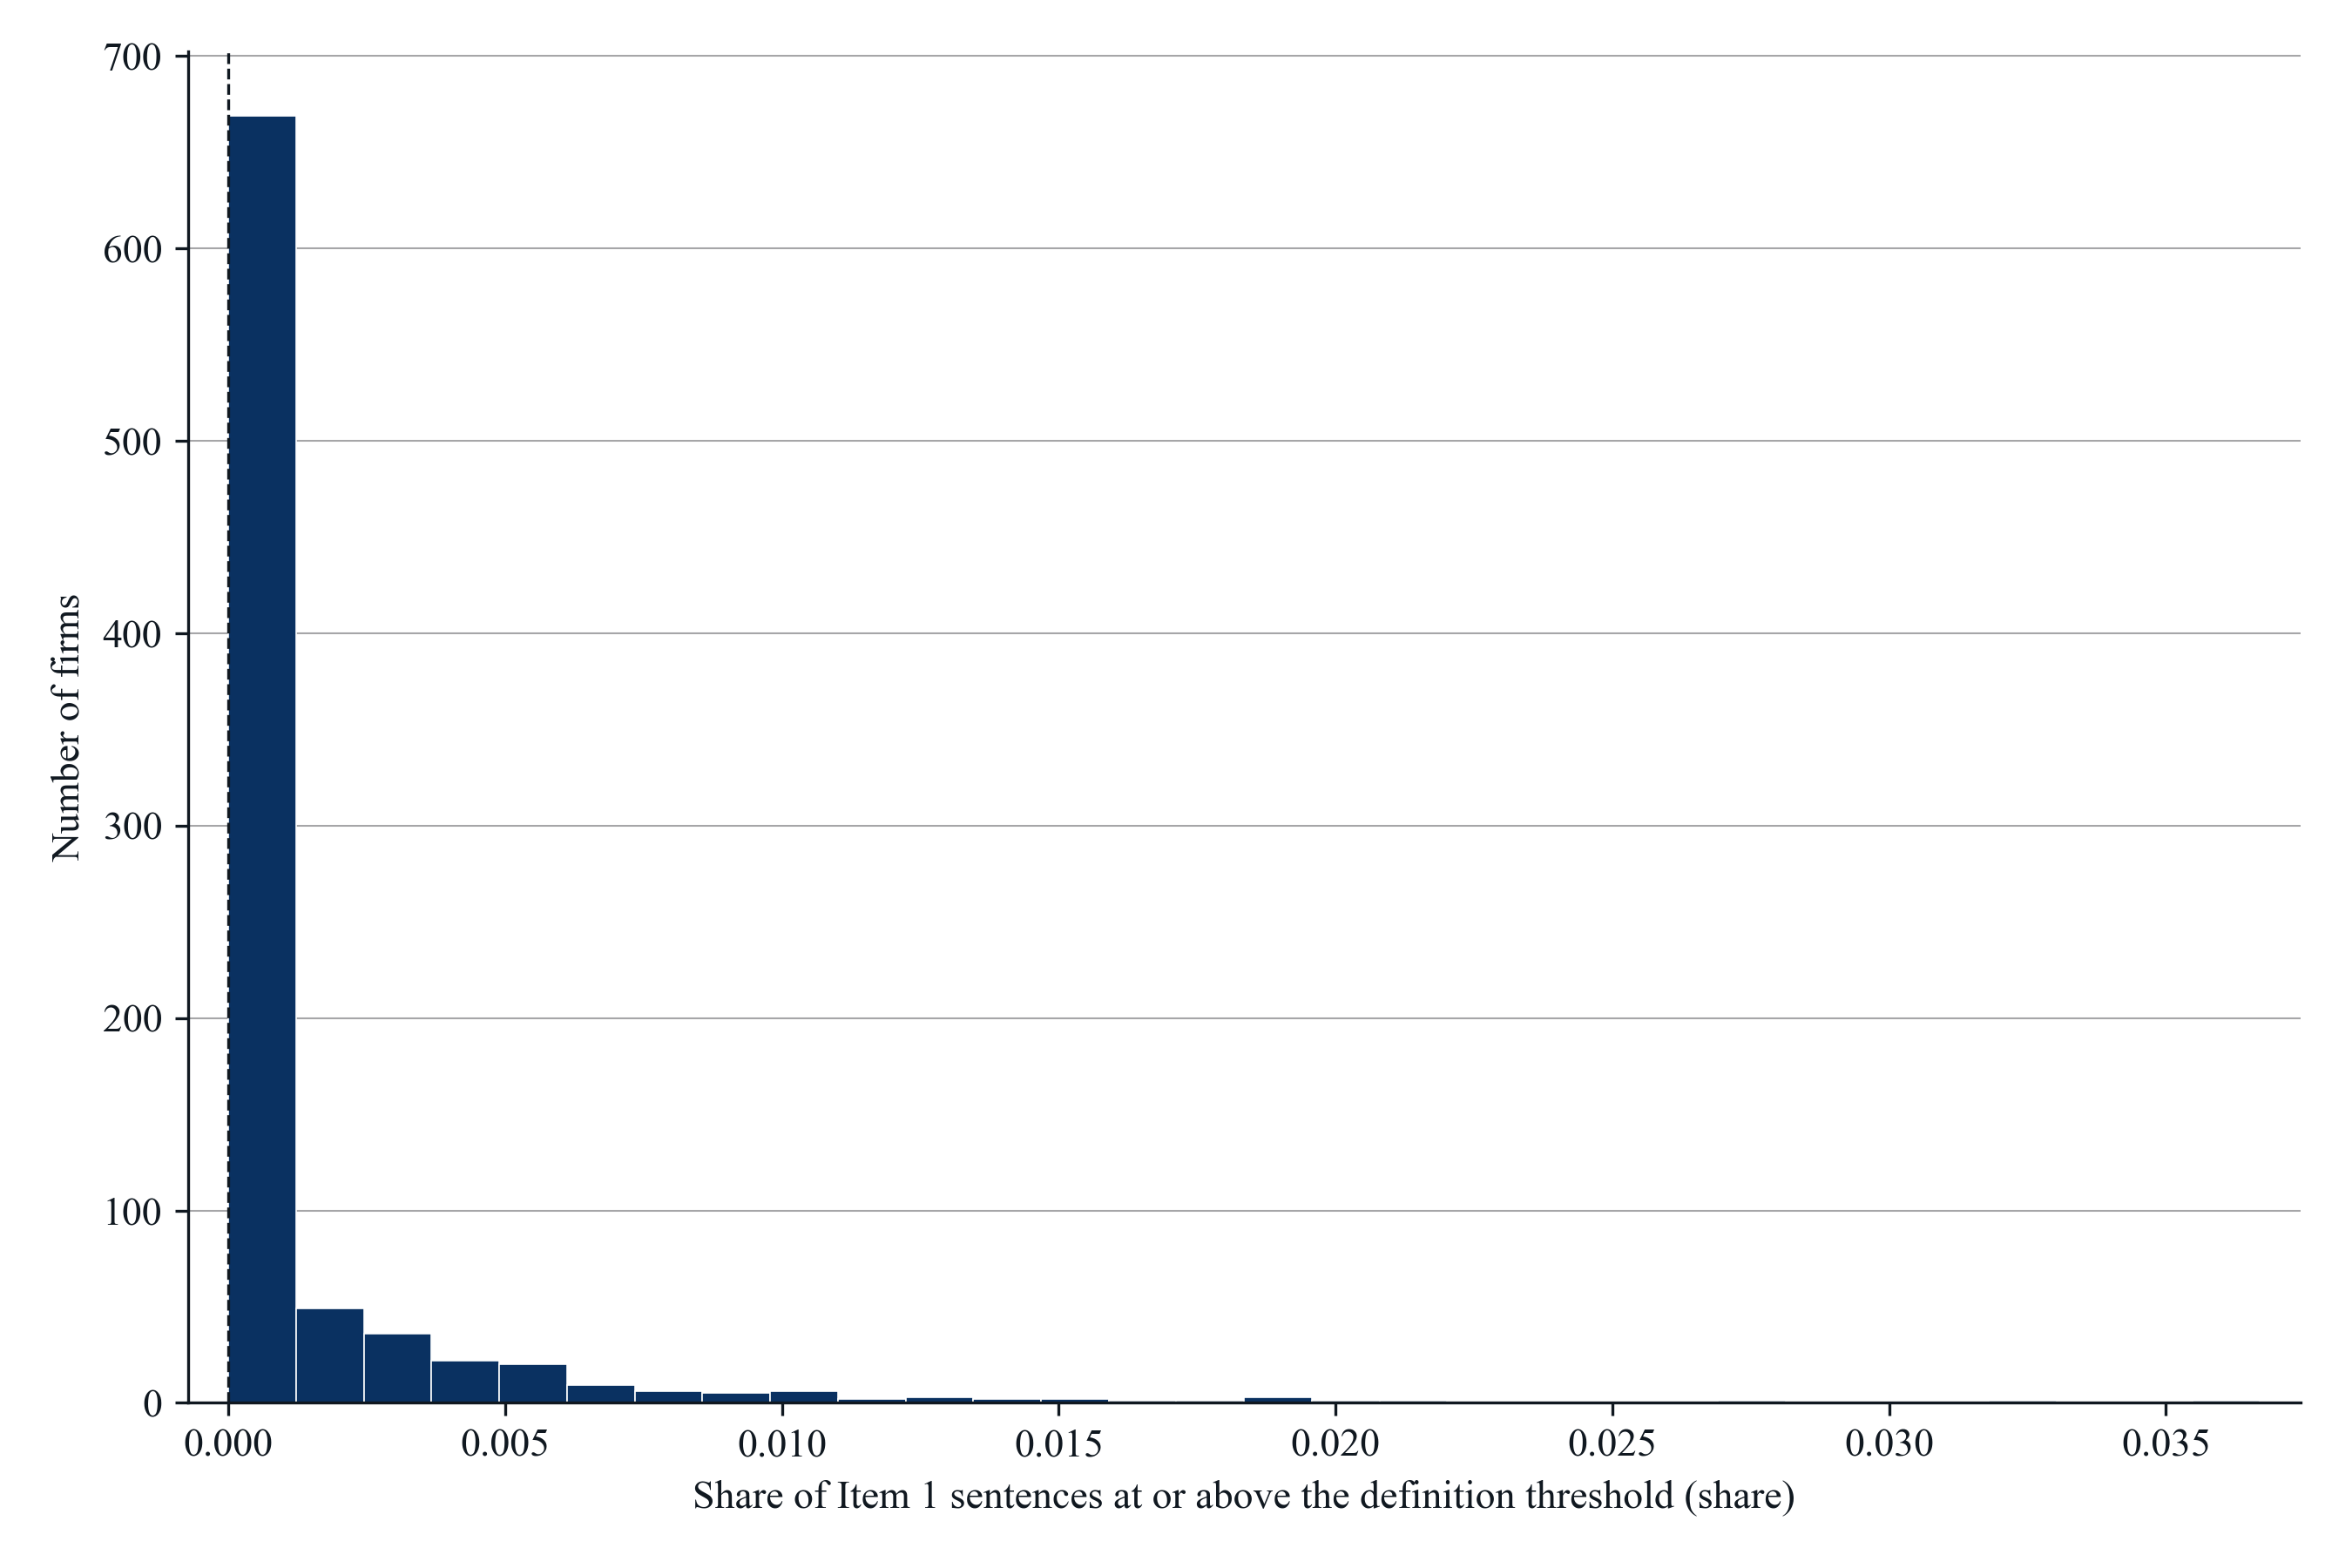

*Notes*: Each bar counts firms in the three-year sample (fiscal years 2010, 2015, and 2020; 841 firms) by their score, which is the number of the firm's Item 1 sentences whose cosine with the topic definition is at or above 0.67, divided by all its Item 1 sentences in the sample, compared with the topic definition of Topic 68, consumer data privacy legislation. 30 bins of equal width from 0.000 to 0.037. The dashed line marks the median, 0.000. 649 of the 841 firms have no sentence at or above the threshold and score 0, so the binary measure for this vector equals 1 for 192 firms.

*Source*: 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; authors' calculations.

**Figure 2. Distribution of the Share of Sentences with the Centroid Vector**

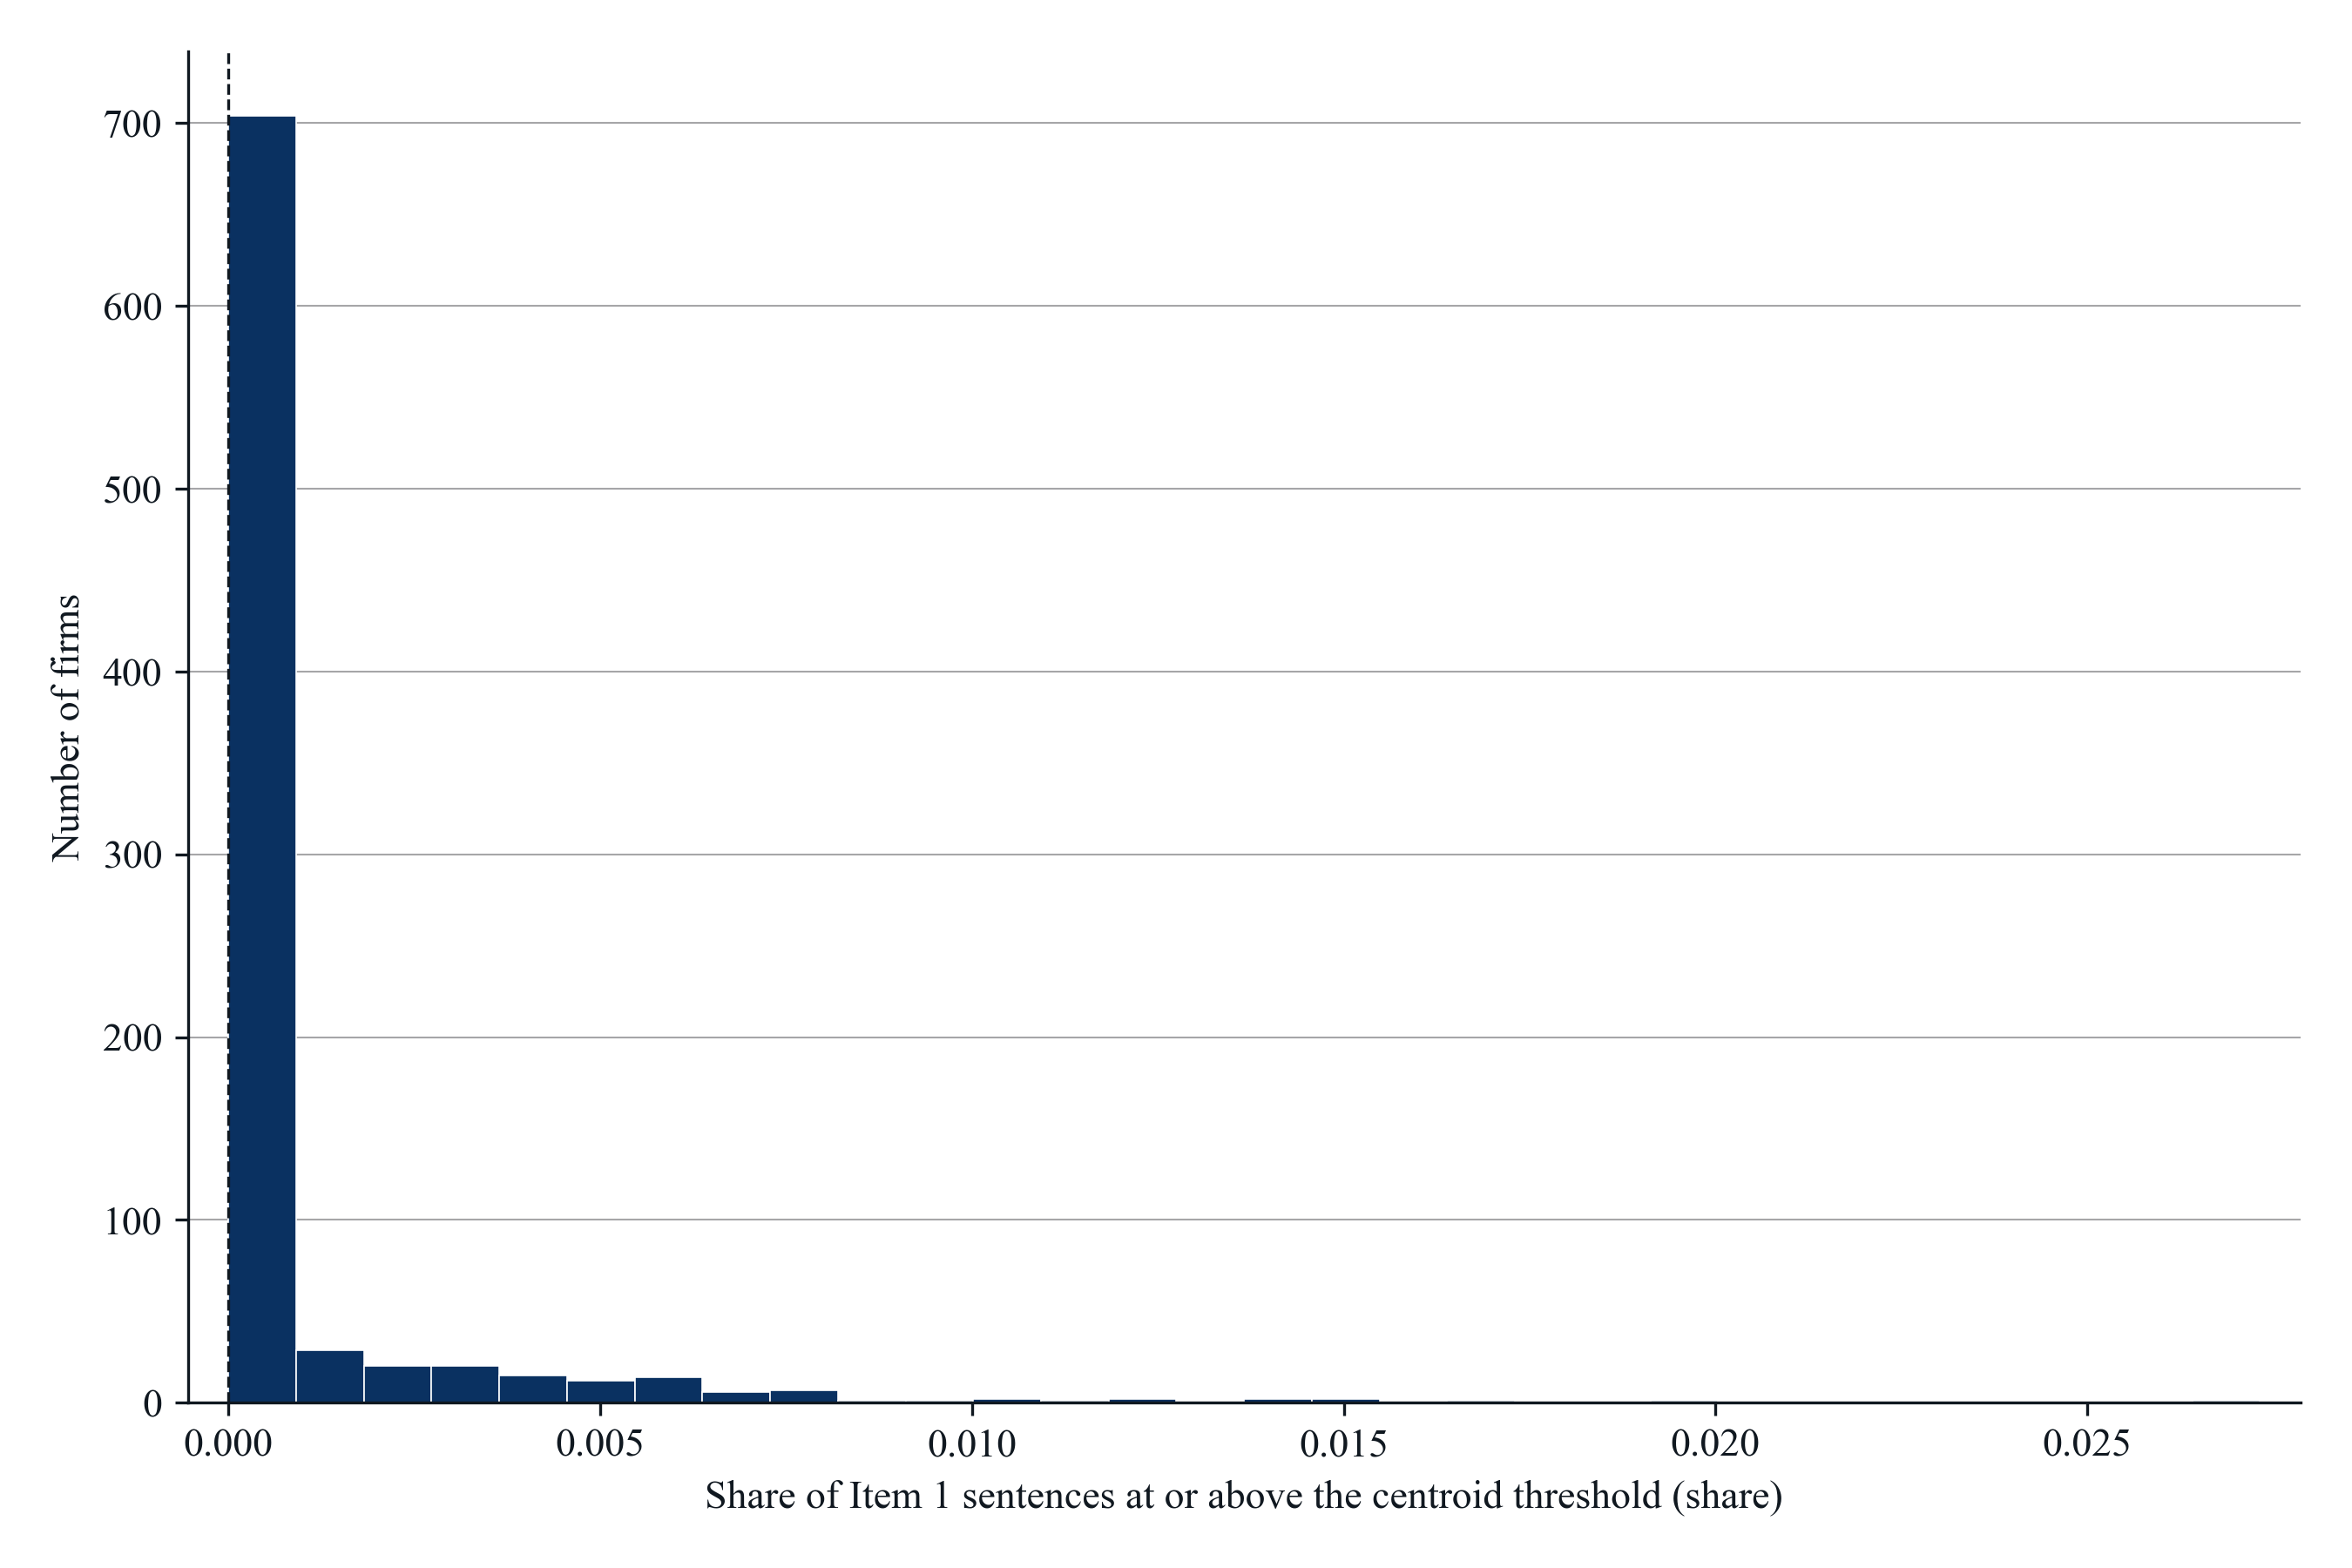

*Notes*: Each bar counts firms in the three-year sample (fiscal years 2010, 2015, and 2020; 841 firms) by their score, which is the number of the firm's Item 1 sentences whose cosine with the statement centroid is at or above 0.75, divided by all its Item 1 sentences in the sample, compared with the statement centroid of Topic 68, consumer data privacy legislation. 30 bins of equal width from 0.000 to 0.027. The dashed line marks the median, 0.000. 679 of the 841 firms have no sentence at or above the threshold and score 0, so the binary measure for this vector equals 1 for 162 firms.

*Source*: 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; authors' calculations.

**Figure 3. Distribution of the Firm Summary Cosine with the Definition Vector**

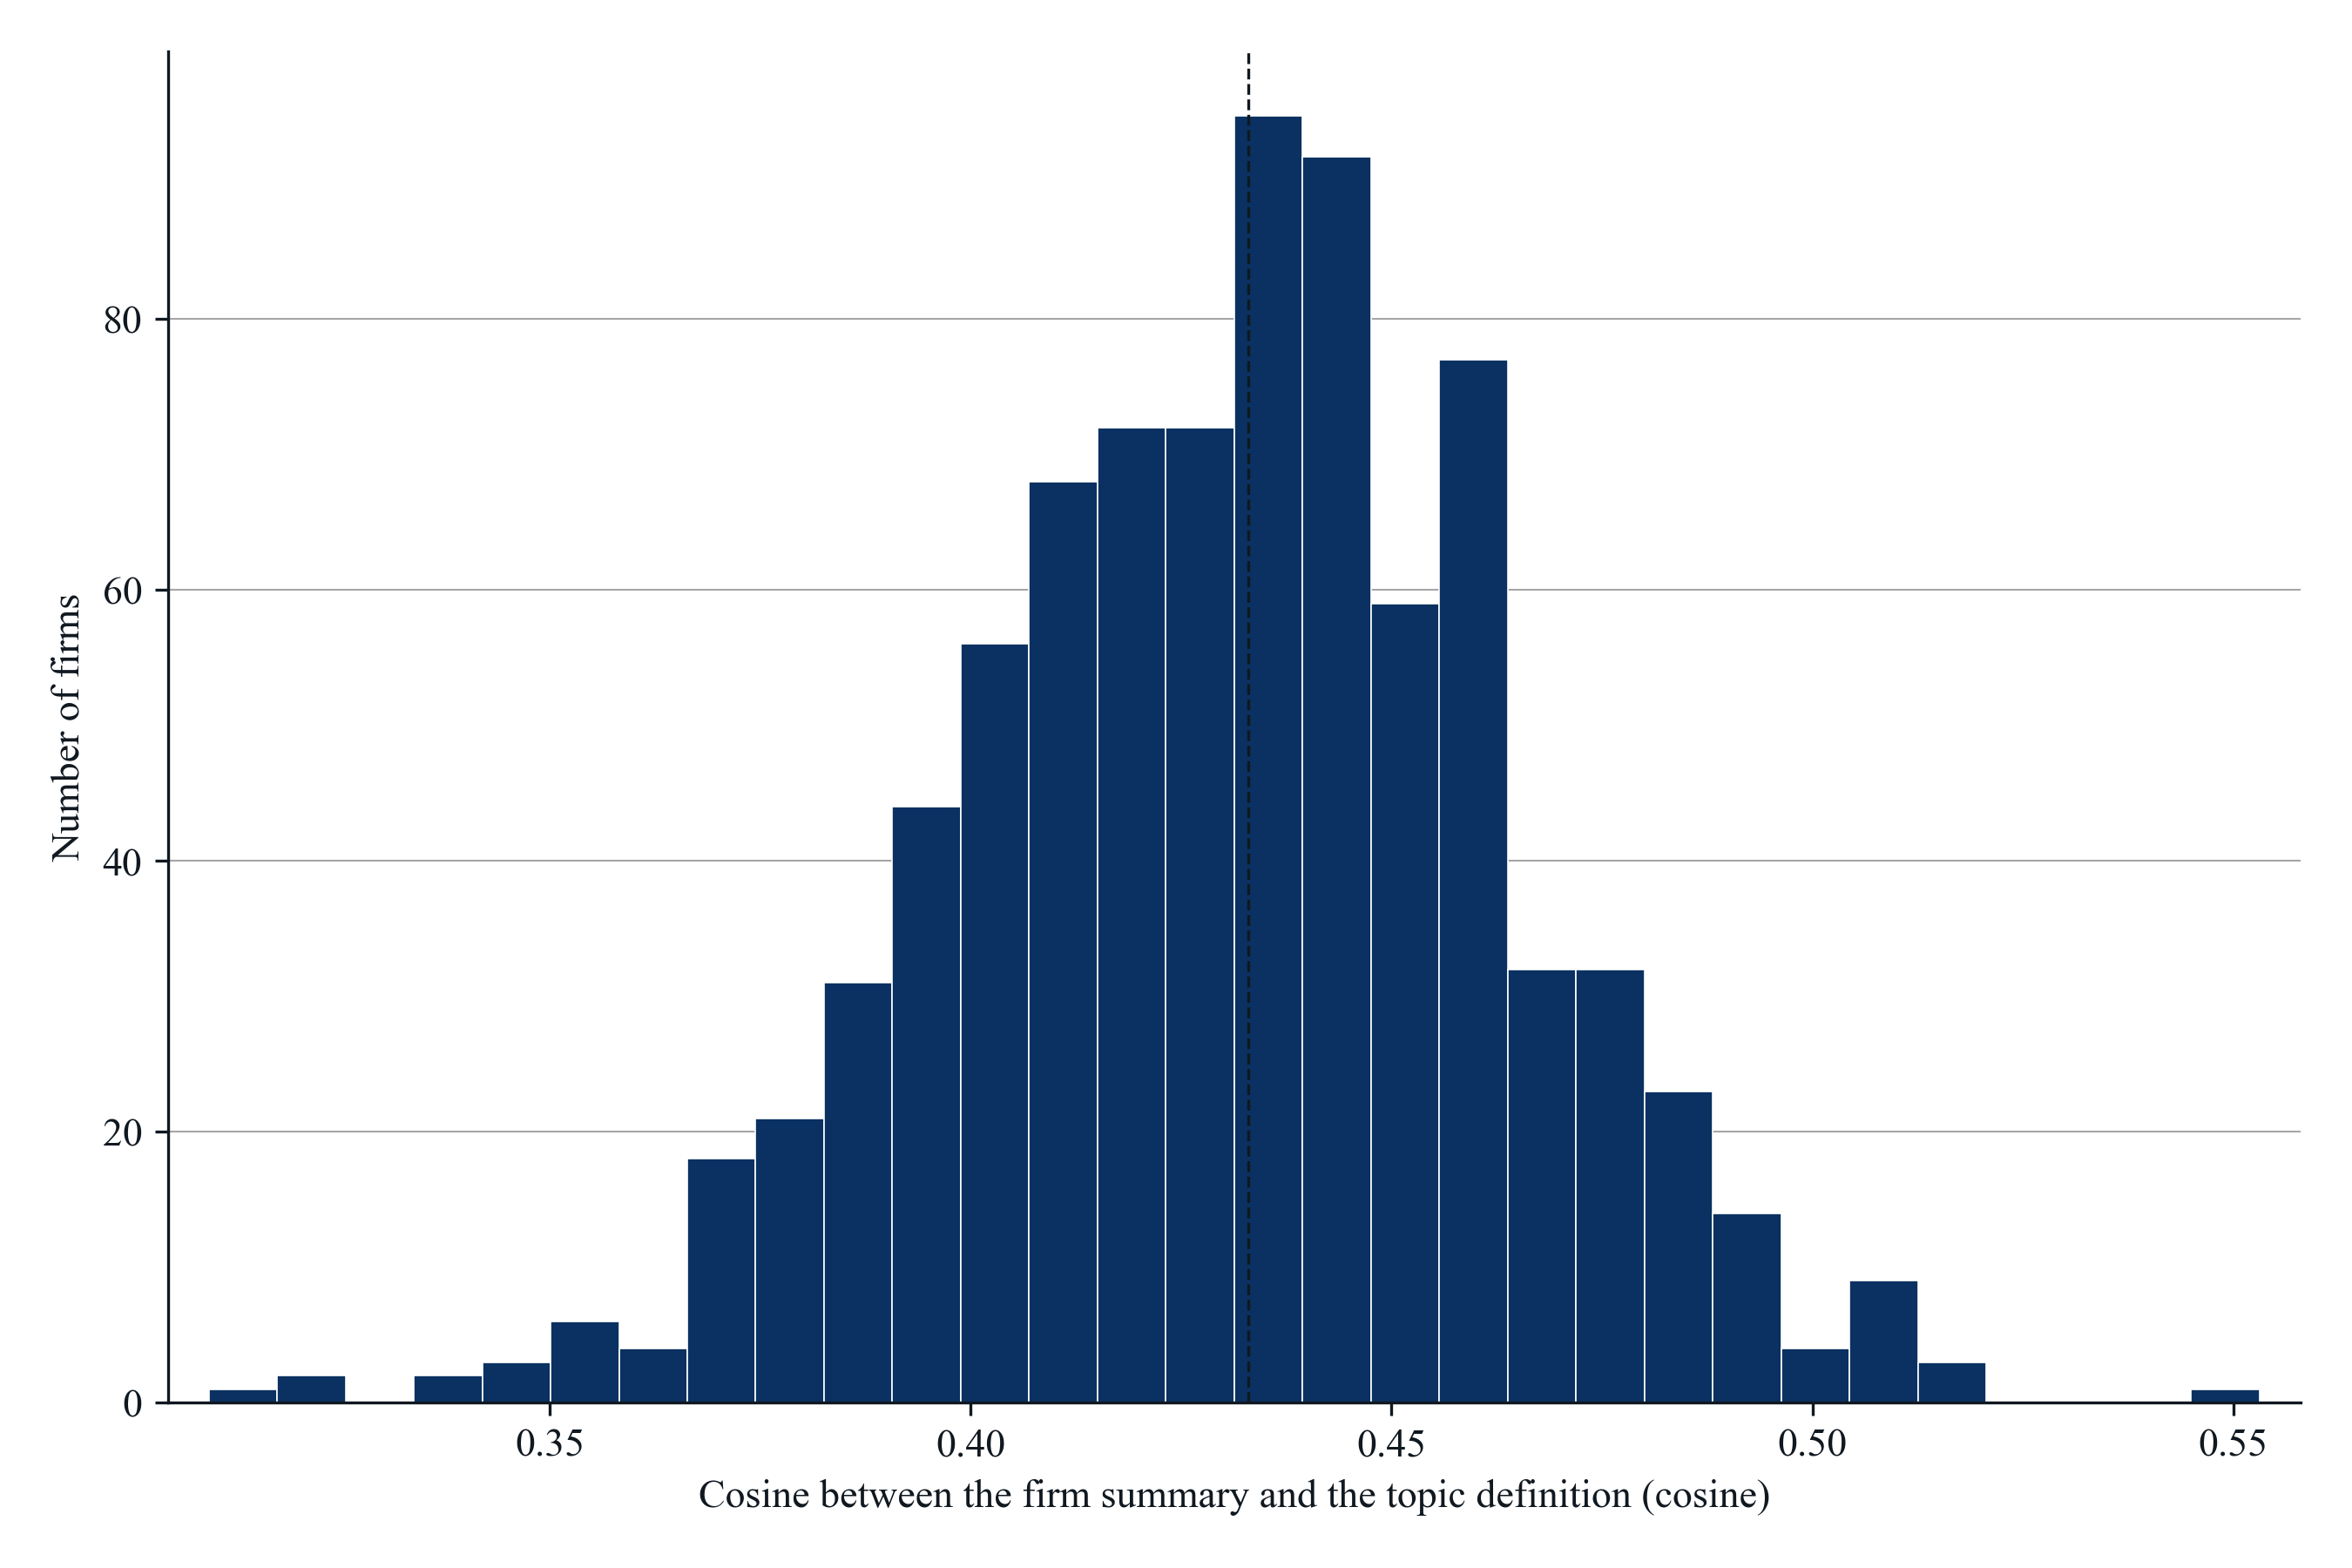

*Notes*: Each bar counts firms in the three-year sample (fiscal years 2010, 2015, and 2020; 841 firms) by their score, which is the cosine between the embedding of the firm's summary of its Item 1 sections and the embedding of the topic definition, compared with the topic definition of Topic 68, consumer data privacy legislation. 30 bins of equal width from 0.309 to 0.553. The dashed line marks the median, 0.433.

*Source*: 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; authors' calculations.

**Figure 4. Distribution of the Yearly Summary Mean Cosine with the Definition Vector**

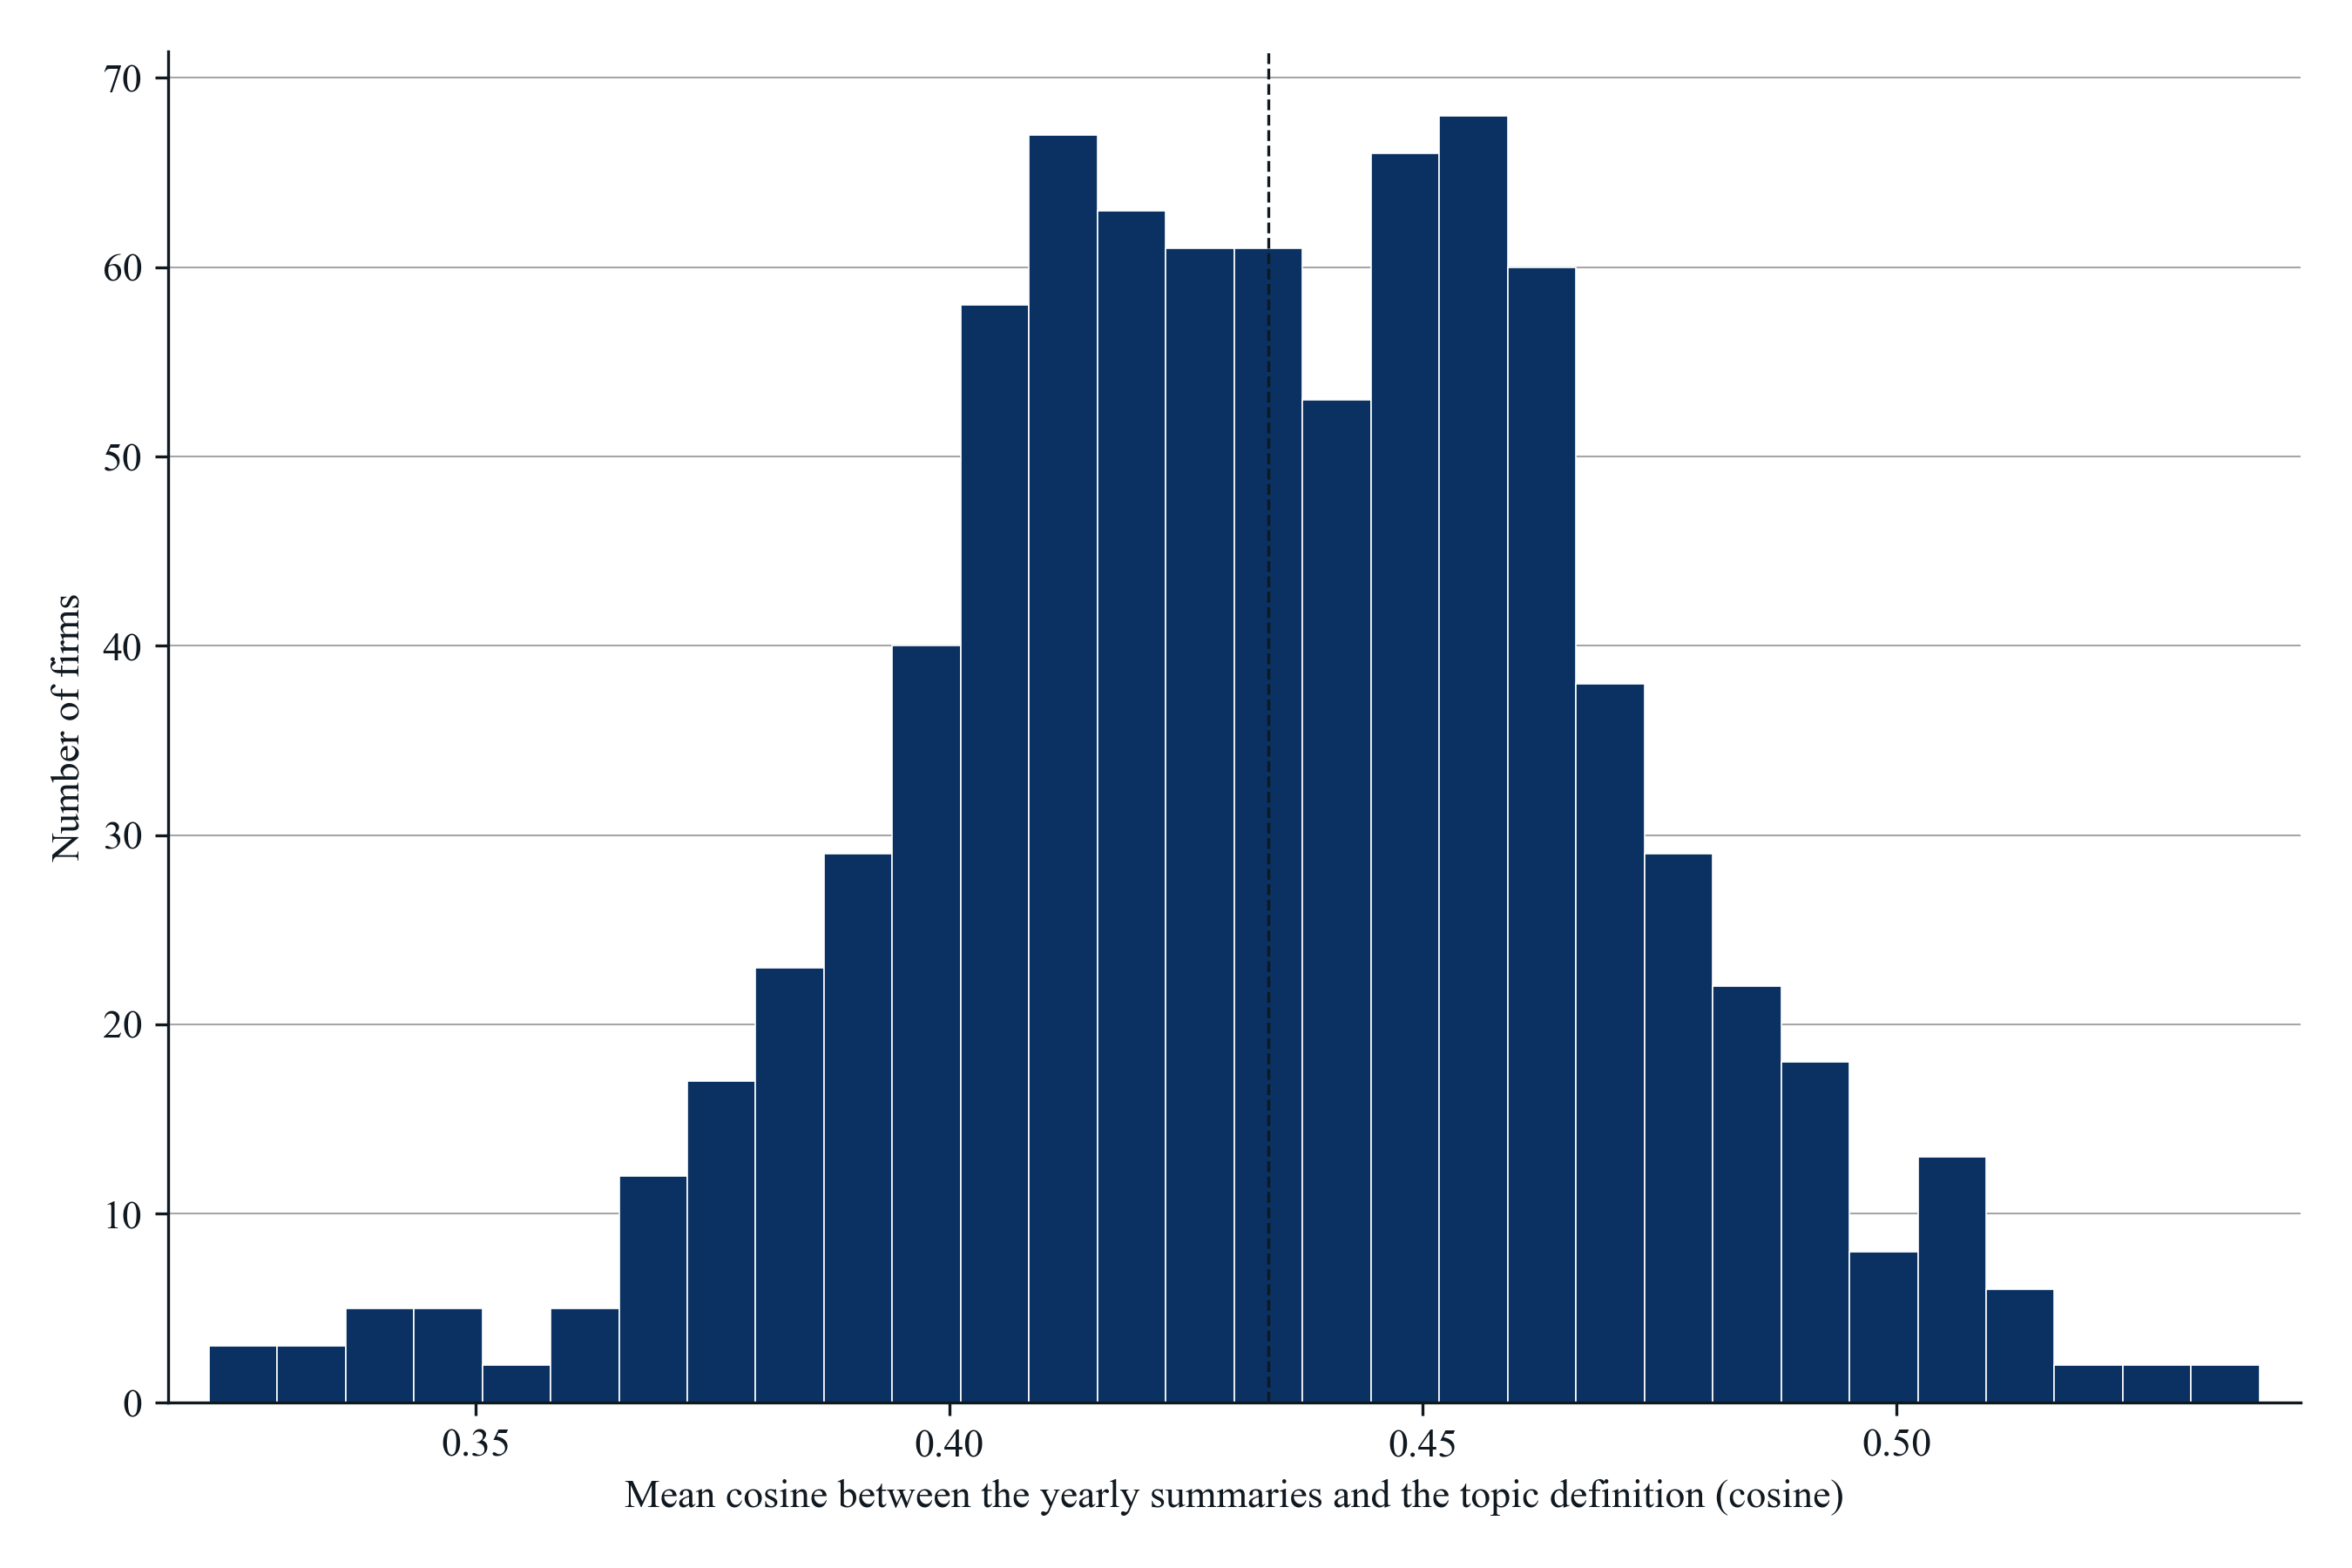

*Notes*: Each bar counts firms in the three-year sample (fiscal years 2010, 2015, and 2020; 841 firms) by their score, which is the cosine between each yearly Item 1 summary and the topic definition, averaged over the firm's fiscal years in the sample, compared with the topic definition of Topic 68, consumer data privacy legislation. 30 bins of equal width from 0.322 to 0.538. The dashed line marks the median, 0.434.

*Source*: 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; authors' calculations.

**Figure 5. Distribution of the Firm Summary Cosine with the Centroid Vector**

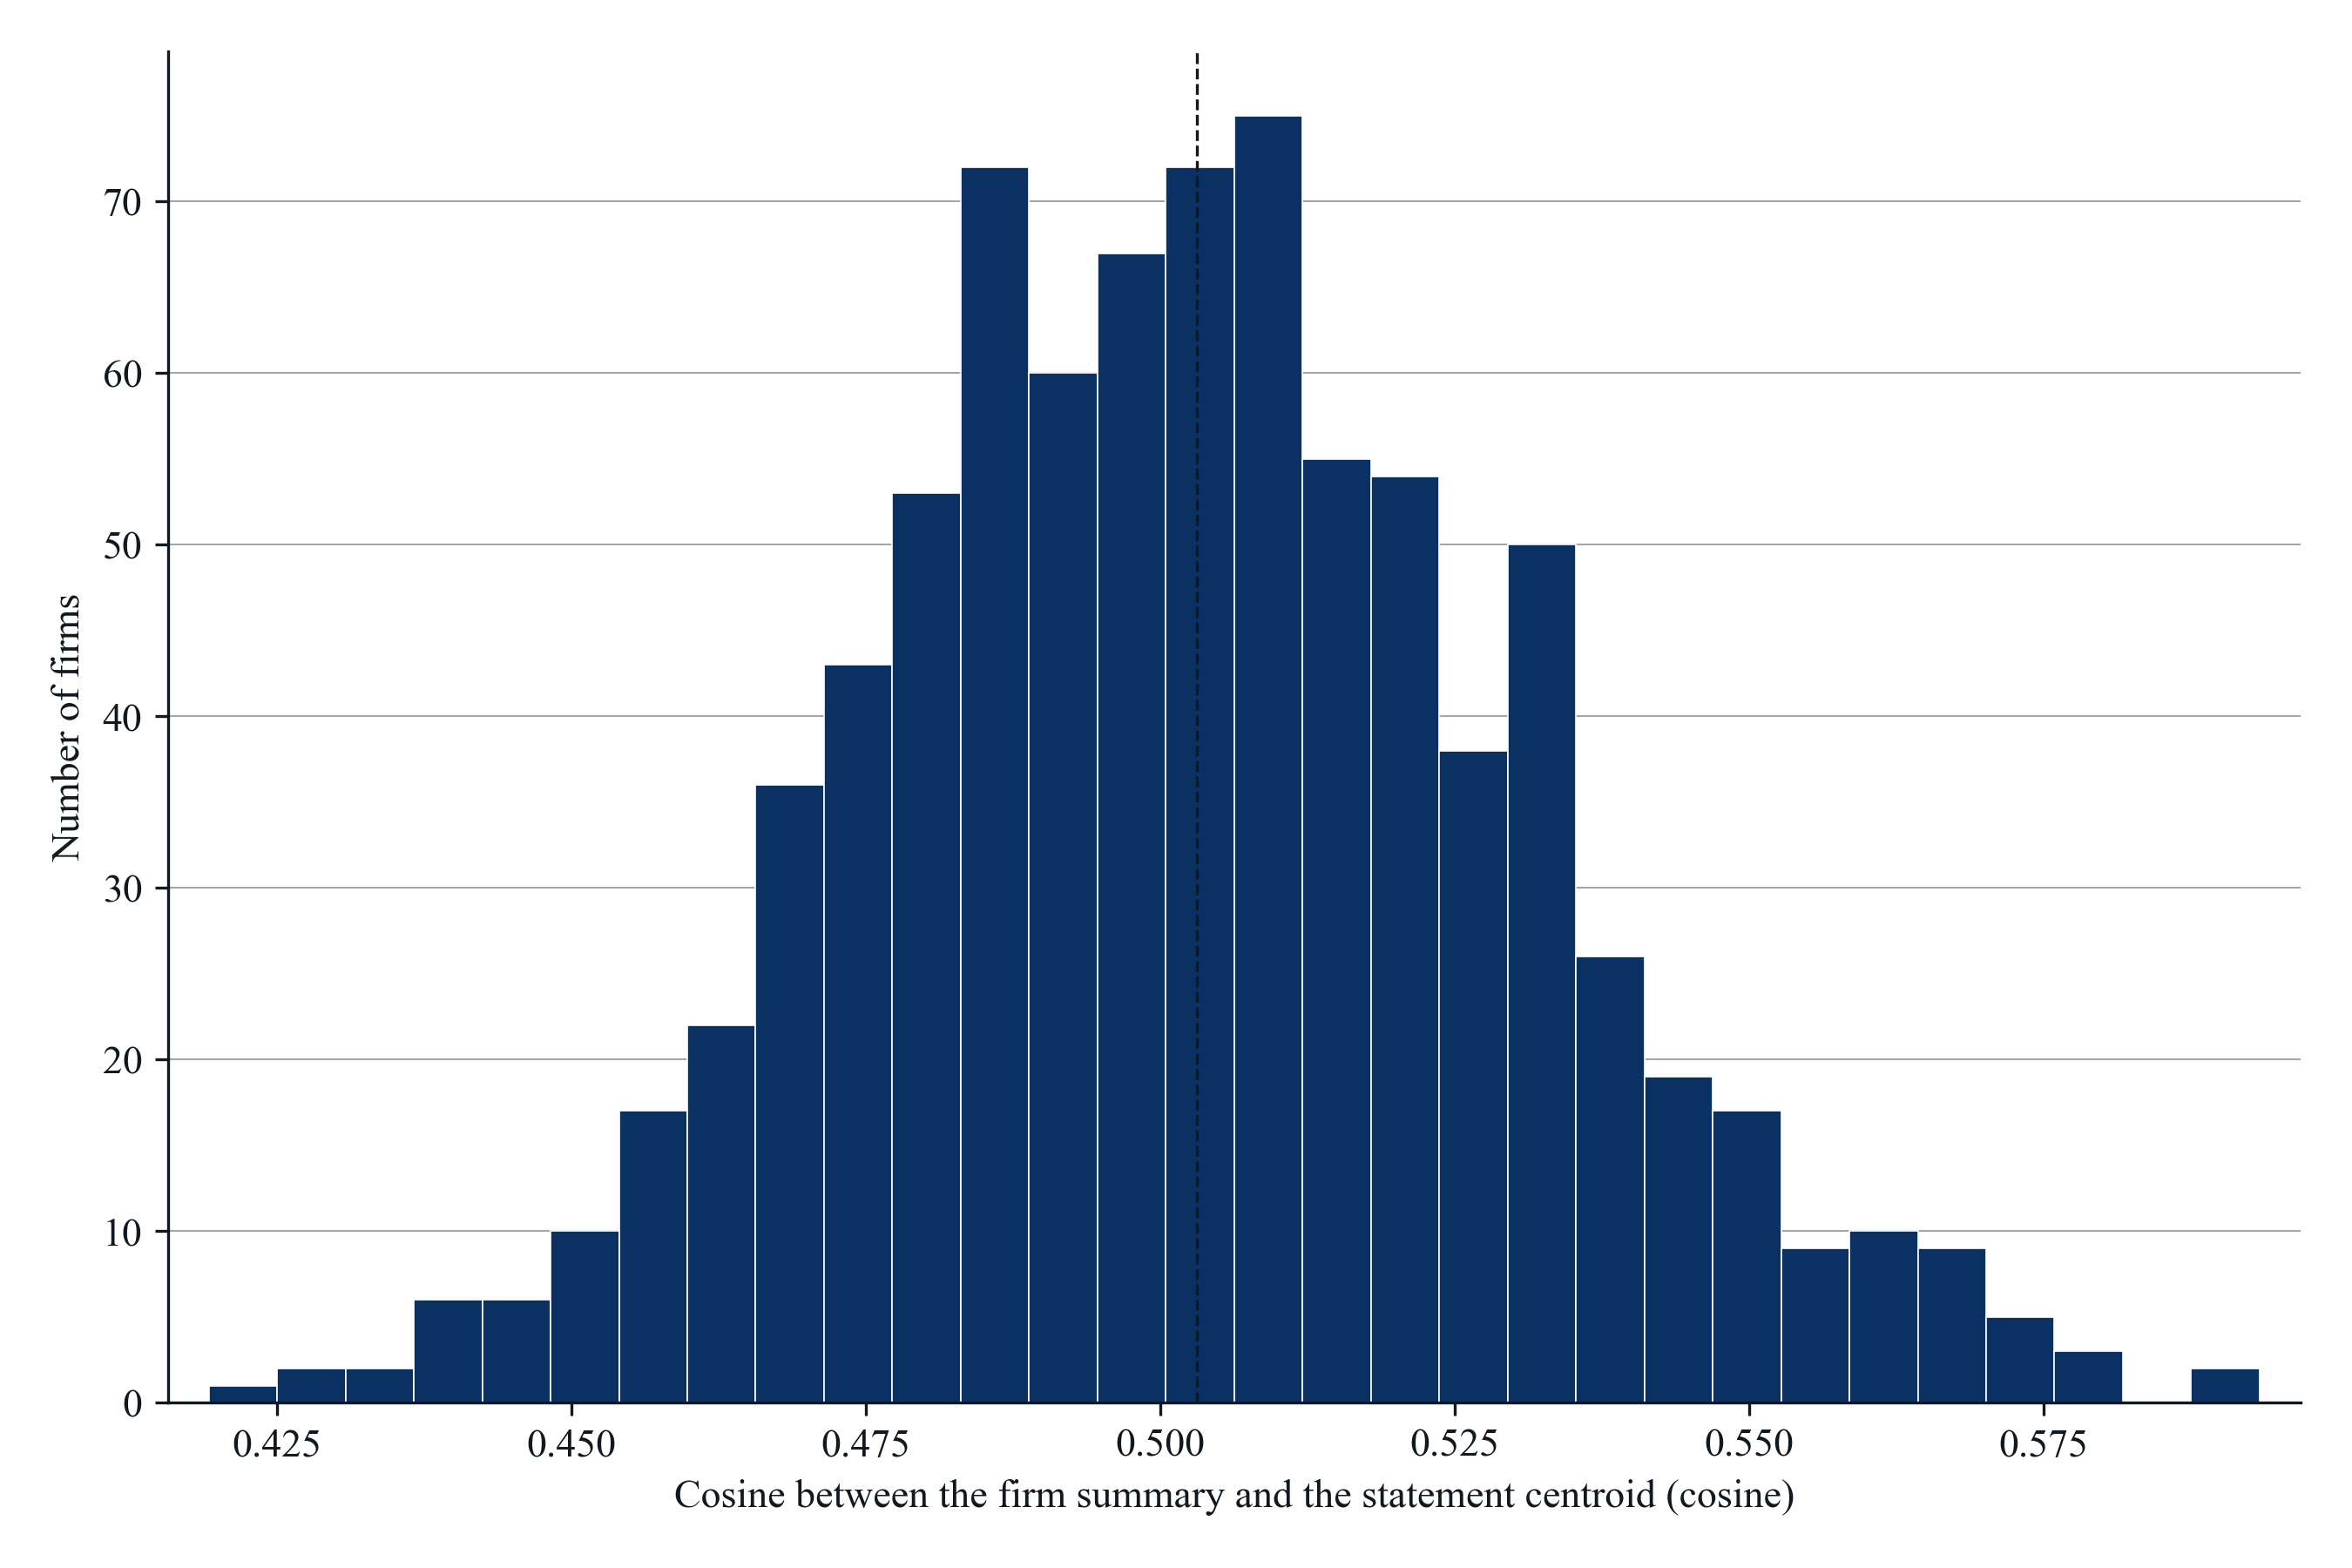

*Notes*: Each bar counts firms in the three-year sample (fiscal years 2010, 2015, and 2020; 841 firms) by their score, which is the cosine between the embedding of the firm's summary of its Item 1 sections and the centroid of the Topic 68 hearing statements, compared with the statement centroid of Topic 68, consumer data privacy legislation. 30 bins of equal width from 0.419 to 0.593. The dashed line marks the median, 0.503.

*Source*: 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; authors' calculations.

**Figure 6. Distribution of the Yearly Summary Mean Cosine with the Centroid Vector**

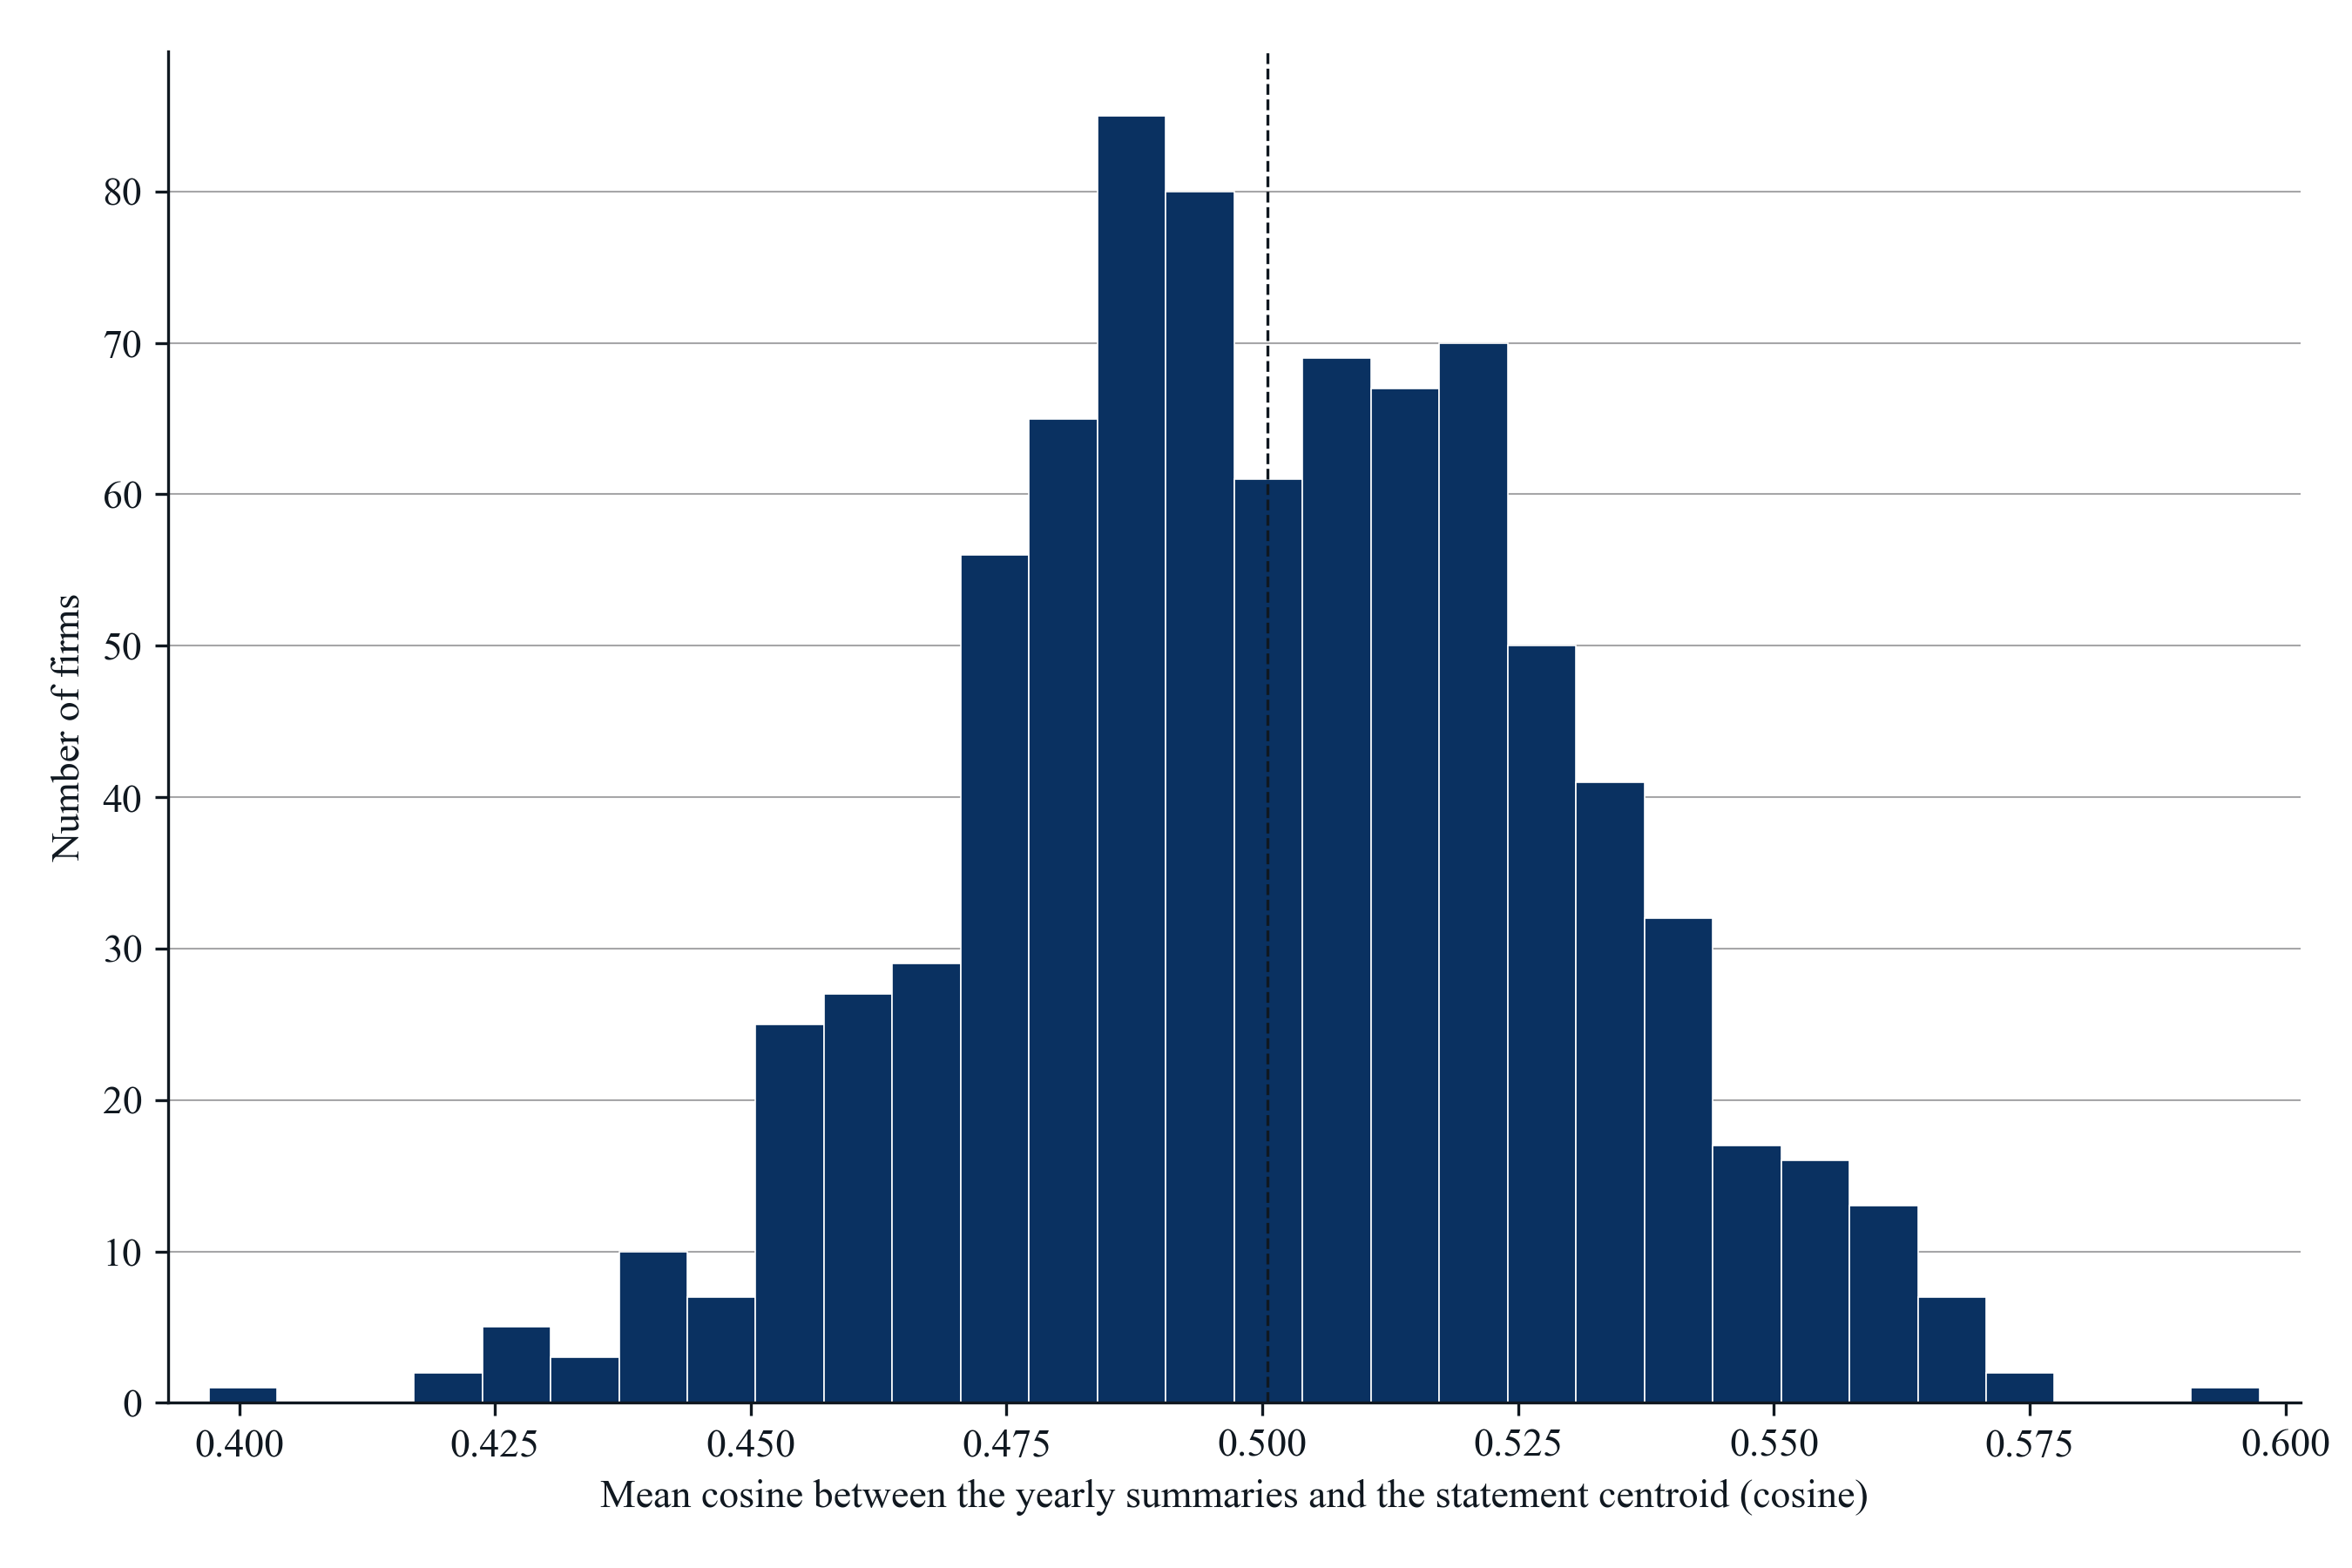

*Notes*: Each bar counts firms in the three-year sample (fiscal years 2010, 2015, and 2020; 841 firms) by their score, which is the cosine between each yearly Item 1 summary and the centroid of the Topic 68 hearing statements, averaged over the firm's fiscal years in the sample, compared with the statement centroid of Topic 68, consumer data privacy legislation. 30 bins of equal width from 0.397 to 0.597. The dashed line marks the median, 0.500.

*Source*: 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; authors' calculations.

**Figure 7. Distribution of the Firm Summary Cosine with the Policy Summary Vector**

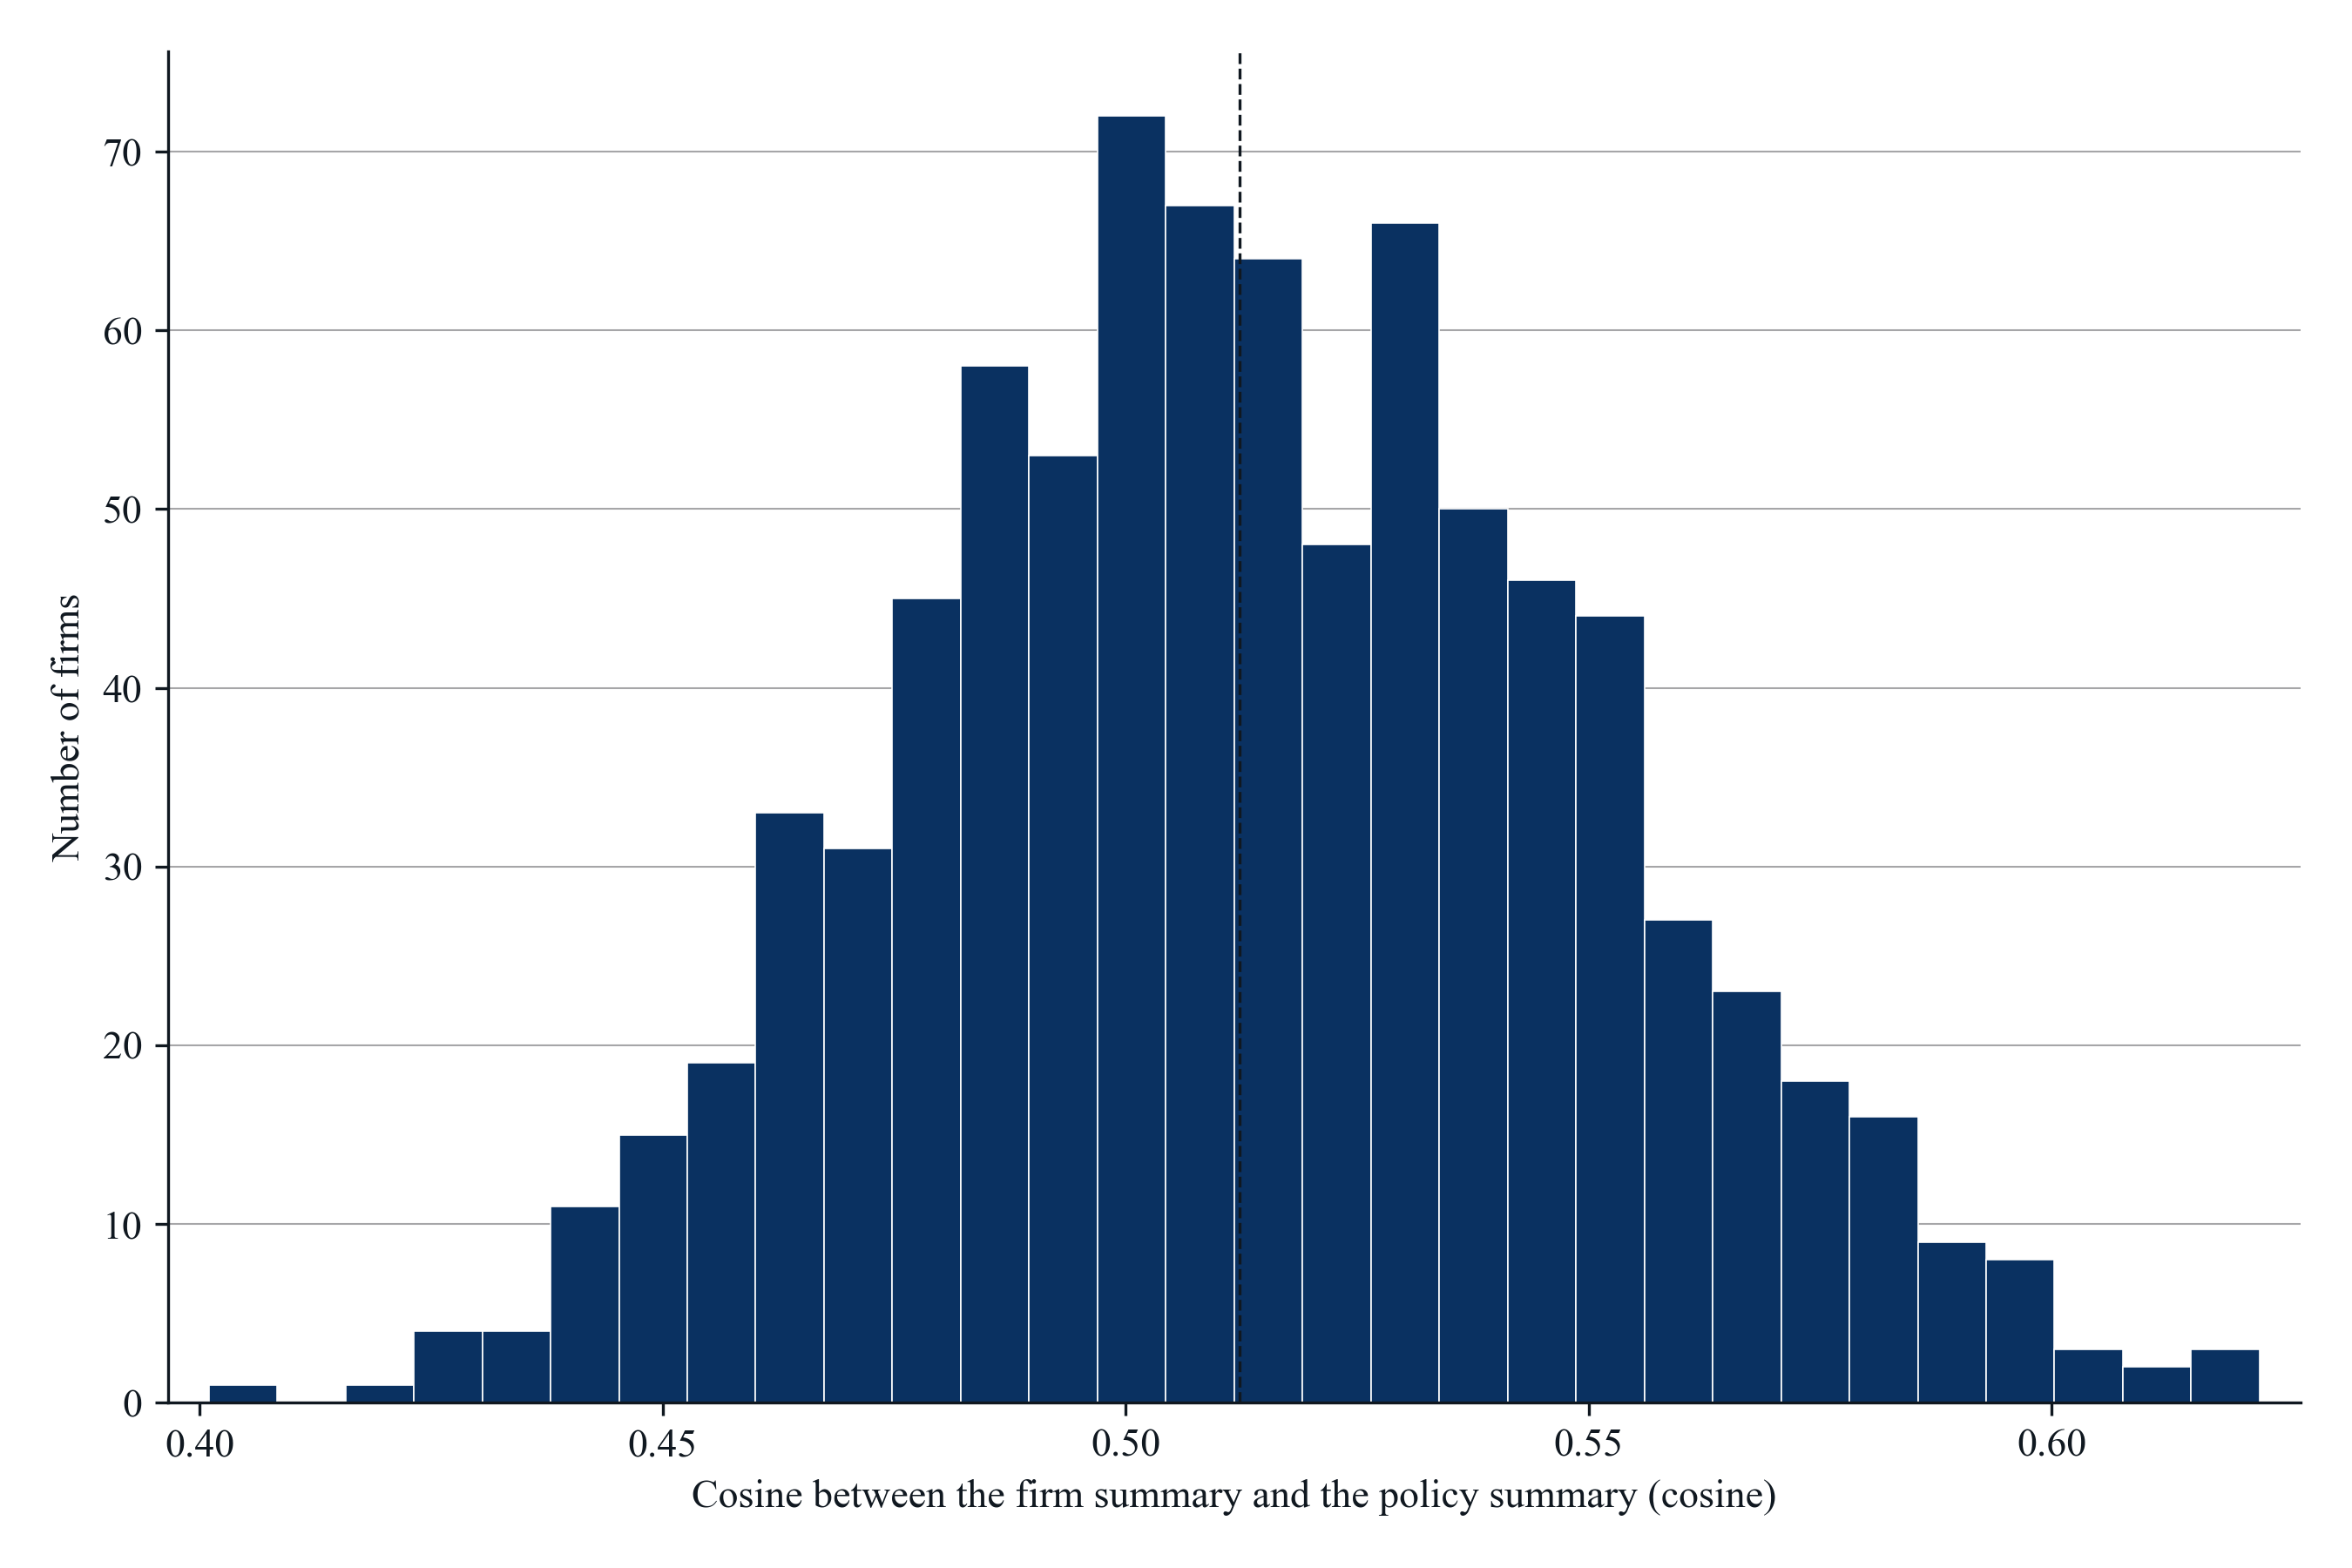

*Notes*: Each bar counts firms in the three-year sample (fiscal years 2010, 2015, and 2020; 841 firms) by their score, which is the cosine between the embedding of the firm's summary of its Item 1 sections and the embedding of the policy summary of the Topic 68 hearing statements, compared with the policy summary of Topic 68, consumer data privacy legislation. 30 bins of equal width from 0.401 to 0.622. The dashed line marks the median, 0.512.

*Source*: 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; authors' calculations.

**Figure 8. Distribution of the Yearly Summary Mean Cosine with the Policy Summary Vector**

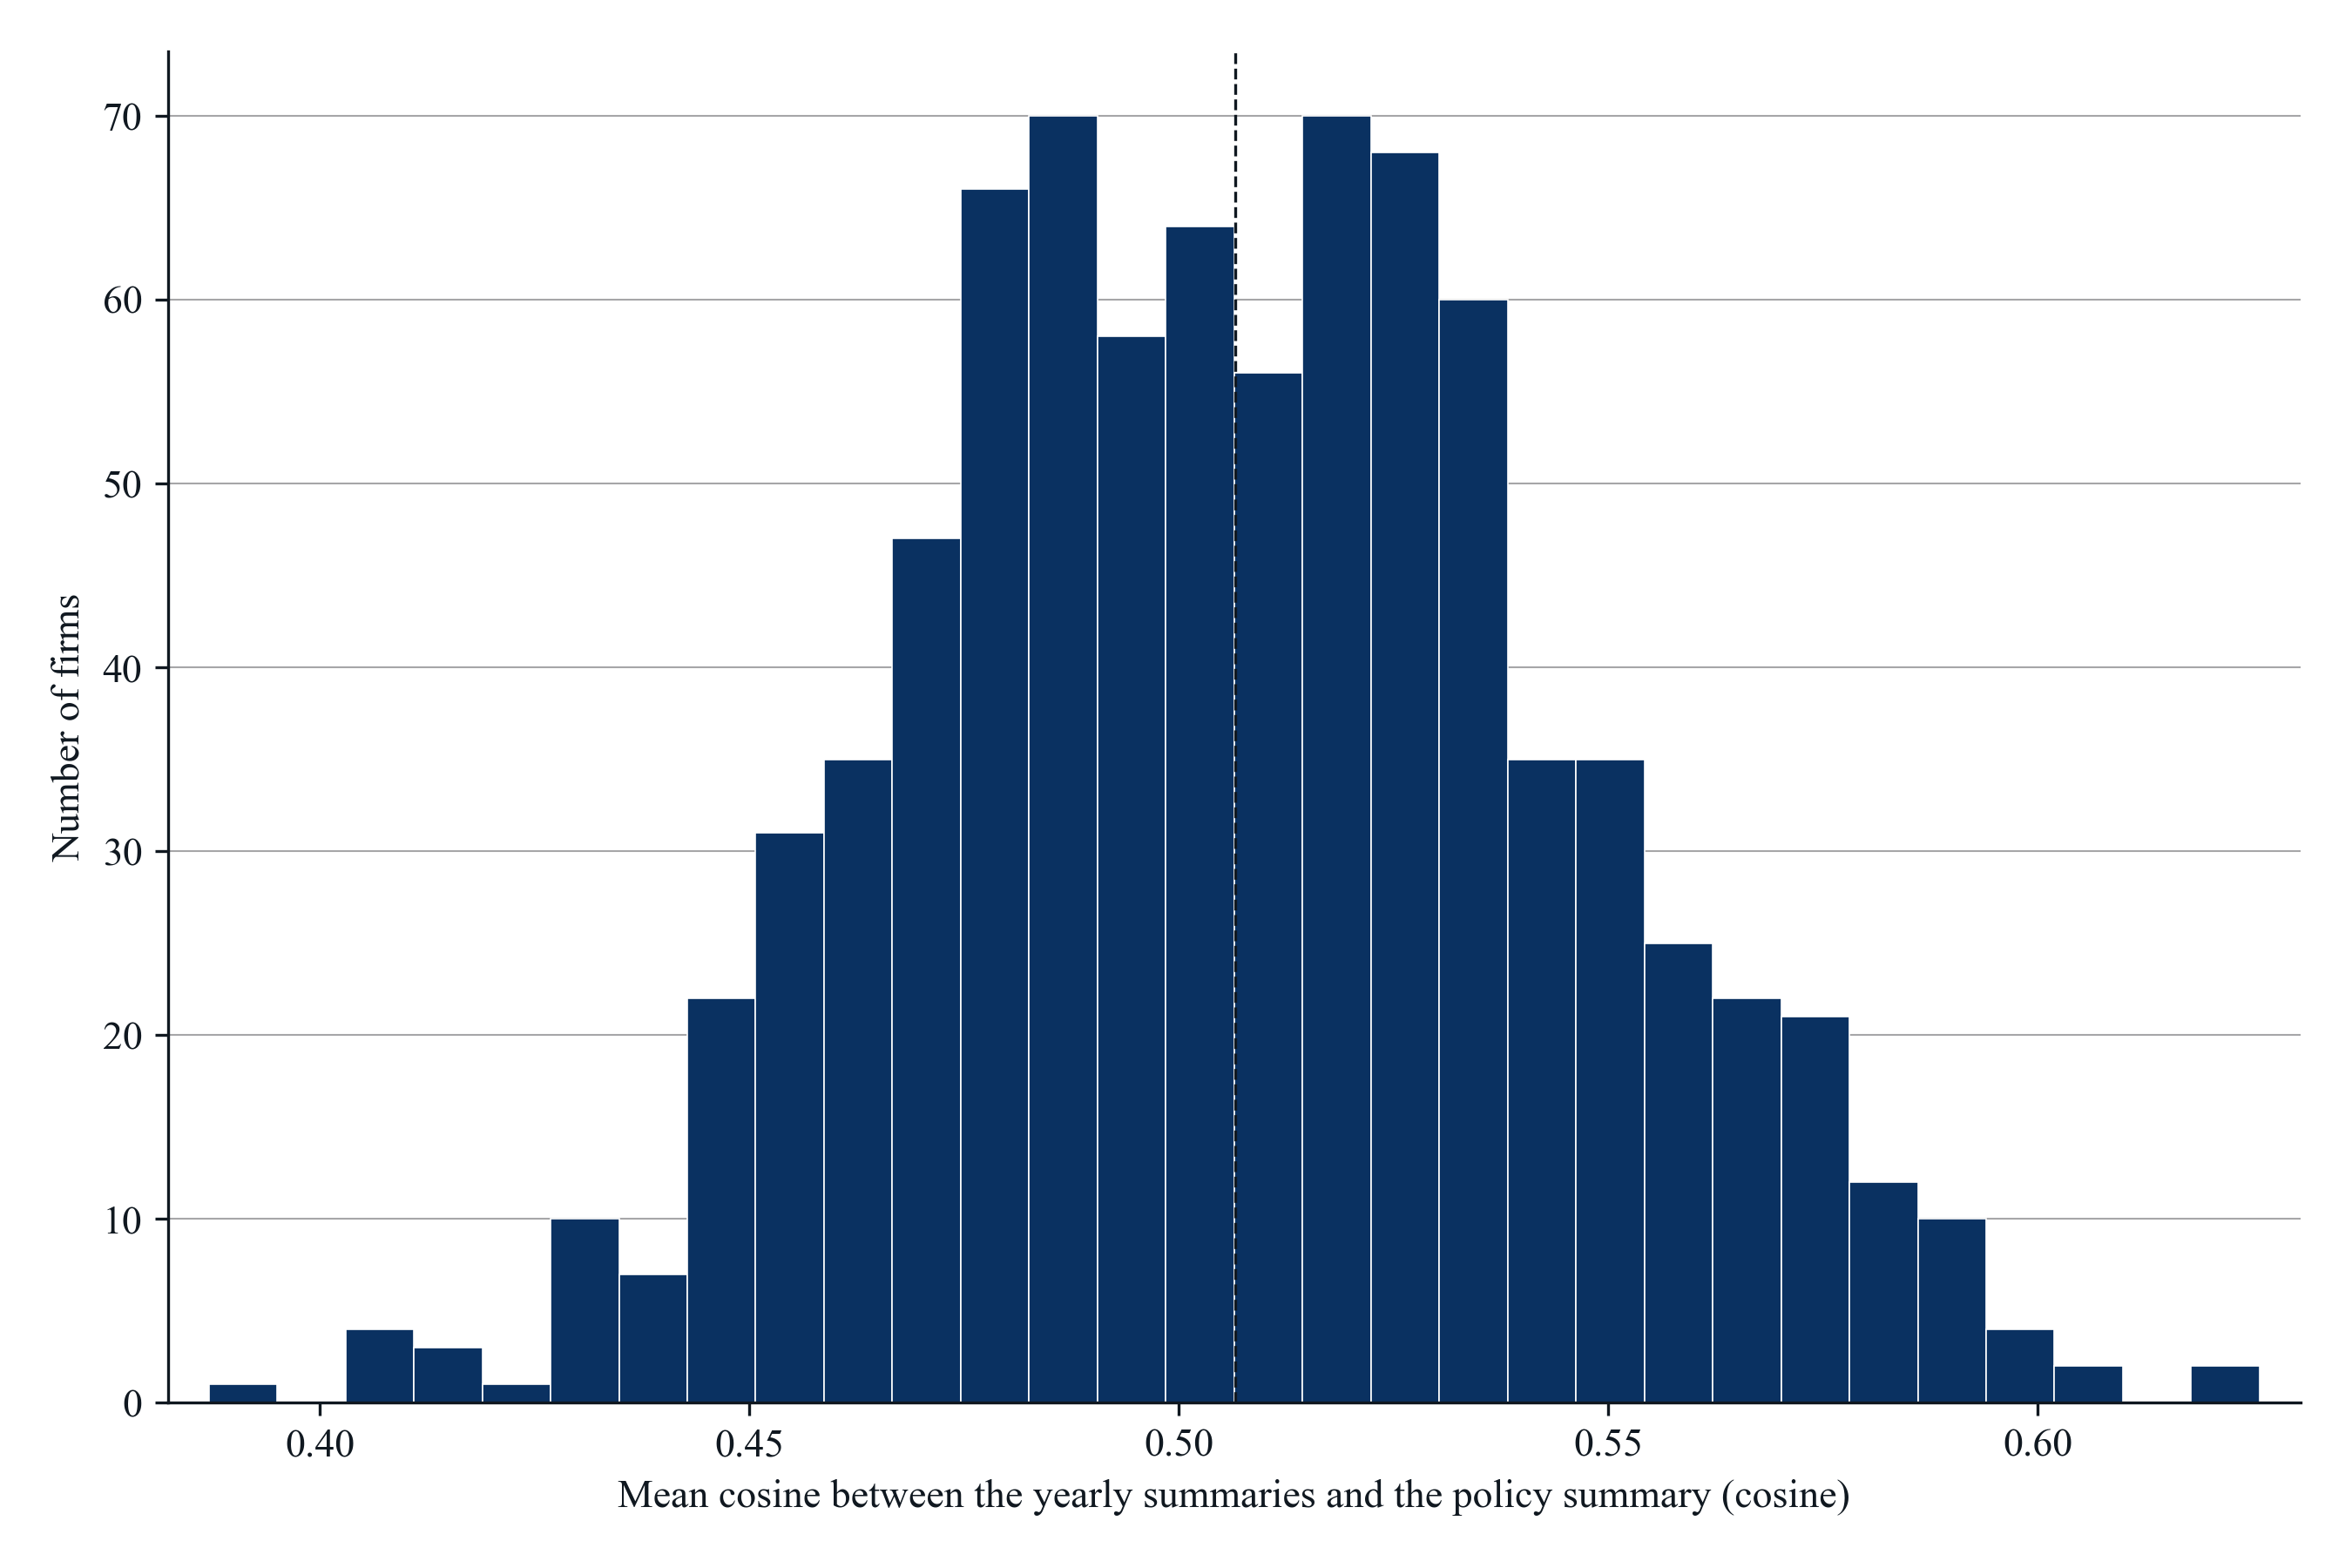

*Notes*: Each bar counts firms in the three-year sample (fiscal years 2010, 2015, and 2020; 841 firms) by their score, which is the cosine between each yearly Item 1 summary and the policy summary of the Topic 68 hearing statements, averaged over the firm's fiscal years in the sample, compared with the policy summary of Topic 68, consumer data privacy legislation. 30 bins of equal width from 0.387 to 0.626. The dashed line marks the median, 0.507.

*Source*: 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; authors' calculations.

In [6]:
TITLE_WORDS = {"sentences": "Sentence", "summaries": "Summary"}
MEASURE_TITLES = {"share": "Share of Sentences", "firm_summary": "Firm Summary Cosine", "yearly_mean": "Yearly Summary Mean Cosine"}
VECTOR_TITLES = {"definition": "Definition Vector", "centroid": "Centroid Vector", "policy_summary": "Policy Summary Vector"}
for figure_number, figure_name, measure_id, notes in figure_records:
    method, vector, measure = [part.strip() for part in measure_id.split("|")]
    display(Markdown(f"**Figure {figure_number}. Distribution of the {MEASURE_TITLES[measure]} with the {VECTOR_TITLES[vector]}**"))
    display(Image(filename=str(OUTPUT_FOLDER / f"{figure_name}.png"), width=900))
    display(Markdown(f"*Notes*: {notes}"))
    display(Markdown(f"*Source*: {SOURCE}."))
